# Marketplace Analytics: поведение пользователей и популярность товаров

**Цель:** понять, как пользователи взаимодействуют с ассортиментом, выделить поведенческие сегменты товаров и проверить, можно ли предсказать активность на следующий день.

Данные: [T-ECD, small/marketplace](https://huggingface.co/datasets/t-tech/T-ECD), семь шардов `01082–01088`. Идентификаторы и числовые атрибуты обезличены; `price` анализируется как показатель в шкале датасета, не как рубли. Покупки и выручка не наблюдаются.

План: качество данных → EDA → пользователи → категории и товары → воронка → сегментация → прогноз → производительность → выводы.

**Запуск:** загрузите `events.parquet` и `items.parquet` в рабочую папку Colab (через левую панель «Файлы»). Сохраните исходные файлы локально: при перезапуске среды файлы Colab могут исчезнуть. CPU достаточно. Все графики выводятся в ноутбук. В ноутбуке сохранены результаты полного запуска на исходных данных, включая повторный регрессионный эксперимент. Для просмотра повторный запуск не нужен.

In [1]:
from pathlib import Path
from time import perf_counter
from collections import Counter
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (silhouette_score, average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score, confusion_matrix, mean_absolute_error,
    mean_squared_error, r2_score)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits

SEED = 42
DATA_DIR = Path('.')  # измените, если файлы лежат в другой папке
ACTIONS = ['view', 'click', 'clickout', 'like']
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 30)

## 1. Загрузка и контроль качества

Сохранённые Parquet-файлы содержат события и атрибуты товаров без тяжёлых эмбеддингов. Не удаляем отрицательный `price`: без описания его преобразования это необоснованная фильтрация. Проверяем ключи каталога, пропуски, события вне каталога и точные дубликаты. Время в исходном наборе представлено `timedelta`, поэтому используем номера дней, а не придумываем календарные даты.

In [2]:
EVENT_COLS = ['timestamp', 'user_id', 'item_id', 'subdomain', 'action_type', 'os']
ITEM_COLS = ['item_id', 'brand_id', 'category', 'subcategory', 'price']
paths = [DATA_DIR / 'events.parquet', DATA_DIR / 'items.parquet']
missing = [str(p) for p in paths if not p.exists()]
if missing:
    raise FileNotFoundError('Загрузите в рабочую папку: ' + ', '.join(missing))
events = pd.read_parquet(paths[0], columns=EVENT_COLS)
items = pd.read_parquet(paths[1], columns=ITEM_COLS)
print(f'События: {len(events):,}; каталог: {len(items):,}')

События: 3,515,262; каталог: 2,325,409


In [3]:
def audit_table(df):
    return pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(),
                         'missing_pct': df.isna().mean().mul(100).round(2)})
print('События:'); display(audit_table(events))
print('Каталог:'); display(audit_table(items))
raw_events, raw_items = len(events), len(items)
events = events.dropna(subset=['timestamp','user_id','item_id','action_type']).drop_duplicates().copy()
items = items.dropna(subset=['item_id']).drop_duplicates().copy()
assert not items['item_id'].duplicated().any(), 'Конфликтующие строки каталога: проверьте item_id'
assert pd.api.types.is_timedelta64_dtype(events['timestamp']), 'Ожидается timedelta в timestamp'
events['day'] = events['timestamp'].dt.days.astype('int32')
events['hour'] = (events['timestamp'].dt.seconds // 3600).astype('int8')
for c in ['action_type','os','subdomain']:
    events[c] = events[c].astype('category')
for c in ['category','subcategory']:
    items[c] = items[c].astype('string').fillna('Unknown').astype('category')
assert events['action_type'].isin(ACTIONS).all(), 'Обнаружены неизвестные типы событий'
missing_catalog = (~events['item_id'].isin(items['item_id'])).sum()
days = sorted(events['day'].unique().tolist())
assert len(days) >= 5 and np.all(np.diff(days)==1), 'Для прогноза нужны минимум 5 последовательных дней'
print(f'Удалено событий: {raw_events-len(events):,}; строк каталога: {raw_items-len(items):,}')
print(f'События без товара в каталоге: {missing_catalog:,}; дни: {days}')
print('Размер таблиц в RAM, МБ:', round((events.memory_usage(deep=True).sum()+items.memory_usage(deep=True).sum())/2**20,1))

События:


,dtype,missing,missing_pct
timestamp,timedelta64[us],0,0.00
user_id,uint64,0,0.00
item_id,object,0,0.00
subdomain,object,1517,0.04
action_type,object,0,0.00
os,object,0,0.00


Каталог:


,dtype,missing,missing_pct
item_id,object,0,0.00
brand_id,uint64,0,0.00
category,object,966395,41.56
subcategory,object,1233023,53.02
price,float64,2882,0.12


Удалено событий: 0; строк каталога: 0
События без товара в каталоге: 0; дни: [1082, 1083, 1084, 1085, 1086, 1087, 1088]
Размер таблиц в RAM, МБ: 471.5


## 2. EDA: объём и динамика взаимодействий

Считаем события, уникальных пользователей и товары, а также долю каждого типа действия. DAU — количество уникальных пользователей с любым наблюдаемым событием в день. Доли действий не являются конверсиями: один человек может многократно просматривать один товар.

Событий: 3,515,262; пользователей: 223,443; товаров с событиями: 185,831
Событий на пользователя: 15.73


,events,share_pct
action_type,,
view,3405630,96.88
click,92749,2.64
clickout,15366,0.44
like,1517,0.04


,events,dau,active_items,events_per_user
day,,,,
1082,500002,58321,42454,8.57
1083,511972,59857,42793,8.55
1084,534733,63260,49476,8.45
1085,494873,58721,46691,8.43
1086,519995,58989,50341,8.82
1087,494059,59691,48152,8.28
1088,459628,56500,46846,8.14


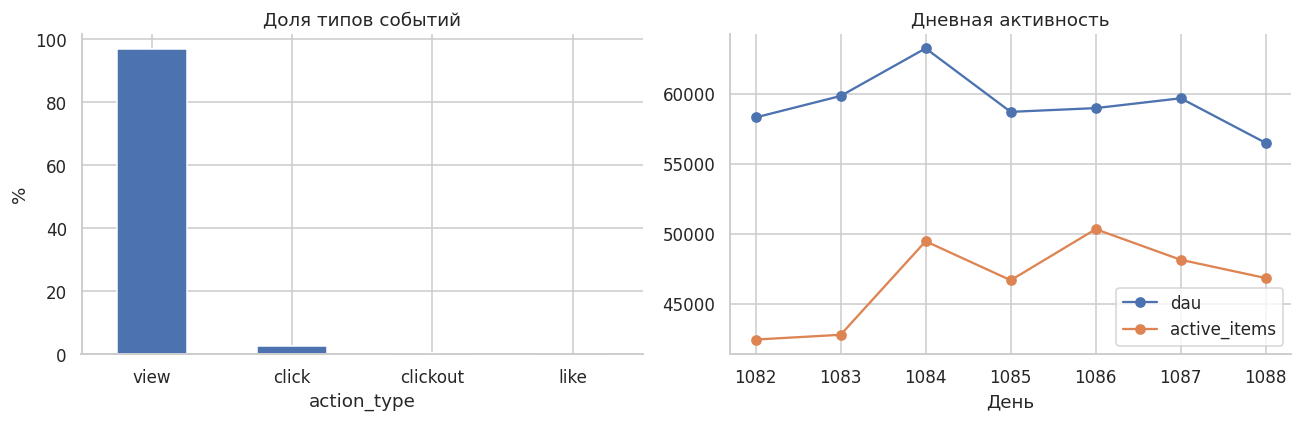

In [4]:
n_events = len(events)
n_users = events['user_id'].nunique()
n_active_items = events['item_id'].nunique()
event_summary = events['action_type'].value_counts().reindex(ACTIONS, fill_value=0).rename('events').to_frame()
event_summary['share_pct'] = event_summary['events']/n_events*100
print(f'Событий: {n_events:,}; пользователей: {n_users:,}; товаров с событиями: {n_active_items:,}')
print(f'Событий на пользователя: {n_events/n_users:.2f}')
display(event_summary.round(2))
daily = events.groupby('day').agg(events=('item_id','size'), dau=('user_id','nunique'), active_items=('item_id','nunique'))
daily['events_per_user'] = daily['events']/daily['dau']
display(daily.round(2))
fig, ax = plt.subplots(1,2,figsize=(12,4))
event_summary['share_pct'].plot.bar(ax=ax[0],rot=0,title='Доля типов событий',ylabel='%')
daily[['dau','active_items']].plot(marker='o',ax=ax[1],title='Дневная активность',xlabel='День')
plt.tight_layout(); plt.show()

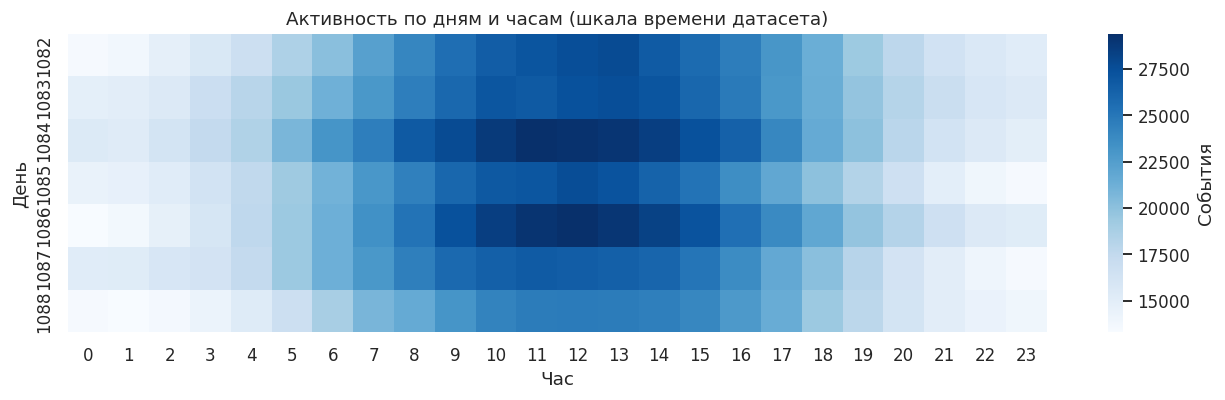

Наиболее активный час по сумме событий: 12


In [5]:
hourly = events.groupby(['day','hour']).size().unstack(fill_value=0).reindex(columns=range(24),fill_value=0)
fig, ax = plt.subplots(figsize=(12,3.8))
sns.heatmap(hourly, cmap='Blues', ax=ax, cbar_kws={'label':'События'})
ax.set(title='Активность по дням и часам (шкала времени датасета)',xlabel='Час',ylabel='День')
plt.tight_layout(); plt.show()
print('Наиболее активный час по сумме событий:', hourly.sum().idxmax())

## 3. Пользовательская аналитика

Изучаем частоту взаимодействий и повторную активность в пределах наблюдаемой недели. Доля пользователей с активностью в несколько дней — не полноценный retention: время первого появления в данных может не совпадать с регистрацией.

Повторная активность (>=2 дней): 45.6%
Медиана событий на пользователя: 6.0


,events,items,active_days
count,223443.00,223443.00,223443.00
mean,15.73,11.38,1.86
std,33.92,23.33,1.30
min,1.00,1.00,1.00
50%,6.00,6.00,1.00
90%,34.00,23.00,3.00
99%,157.00,108.00,7.00
max,1554.00,1094.00,7.00


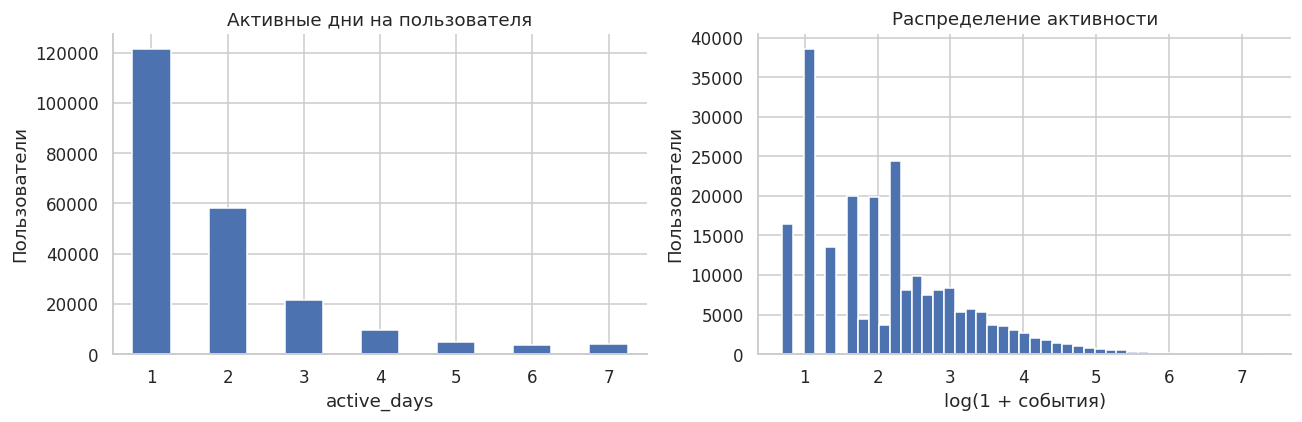

In [6]:
users = events.groupby('user_id',sort=False).agg(events=('item_id','size'), items=('item_id','nunique'), active_days=('day','nunique'))
user_days = users['active_days'].value_counts().sort_index()
repeat_share = users['active_days'].gt(1).mean()
print(f'Повторная активность (>=2 дней): {repeat_share:.1%}')
print('Медиана событий на пользователя:', users['events'].median())
display(users.describe(percentiles=[.5,.9,.99]).round(2))
fig, ax = plt.subplots(1,2,figsize=(12,4))
user_days.plot.bar(ax=ax[0],rot=0,title='Активные дни на пользователя',ylabel='Пользователи')
ax[1].hist(np.log1p(users['events']),bins=45); ax[1].set(title='Распределение активности',xlabel='log(1 + события)',ylabel='Пользователи')
plt.tight_layout(); plt.show()

## 4. Товары и категории

Агрегируем события до уровня товара. Отдельно считаем охват каталога и долю внимания, которую получает верхний 1% активных товаров. Категории с неизвестным значением выделяем отдельно. Сравниваем долю активных товаров и событий на активный товар, а не только абсолютное число просмотров.

In [7]:
def product_features(frame):
    counts = frame.groupby(['item_id','action_type'],observed=True,sort=False).size().unstack(fill_value=0).reindex(columns=ACTIONS,fill_value=0)
    counts.columns = ['n_'+c for c in counts.columns]
    g = frame.groupby('item_id',sort=False)
    counts['total'] = counts.sum(axis=1)
    counts['unique_users'] = g['user_id'].nunique()
    counts['active_days'] = g['day'].nunique()
    for a in ['click','clickout','like']:
        counts[a+'_share'] = counts['n_'+a]/counts['total']
    return counts.reset_index()

products = product_features(events)
products = products.merge(items[['item_id','category','price']],on='item_id',how='left',validate='one_to_one')
products['category'] = products['category'].astype('string').fillna('Unknown')
active_catalog = items['item_id'].isin(products['item_id']).sum()
coverage = active_catalog/len(items)
ranked = products['total'].sort_values(ascending=False).to_numpy()
top_n = max(1,int(np.ceil(len(ranked)*.01)))
top_share = ranked[:top_n].sum()/ranked.sum()
print(f'Охват каталога: {coverage:.2%}; доля событий топ-1% активных товаров: {top_share:.2%}')
cat_catalog = items.groupby('category',observed=True).size().rename('catalog_items')
cat_active = products.groupby('category').agg(active_items=('item_id','size'), events=('total','sum'),views=('n_view','sum'),clicks=('n_click','sum'))
# Для охвата категории считаем только товары, действительно найденные в каталоге.
cat_matched = items.loc[items['item_id'].isin(products['item_id'])].groupby('category',observed=True).size().rename('matched_active_items')
category_summary = cat_catalog.to_frame().join(cat_active,how='outer').join(cat_matched).fillna(0)
category_summary['active_pct'] = 100*category_summary['matched_active_items']/category_summary['catalog_items'].replace(0,np.nan)
category_summary['events_per_active_item'] = category_summary['events']/category_summary['active_items'].replace(0,np.nan)
category_summary['clicks_per_100_views'] = 100*category_summary['clicks']/category_summary['views'].replace(0,np.nan)
display(category_summary.sort_values('events',ascending=False).round(2))

Охват каталога: 7.99%; доля событий топ-1% активных товаров: 81.71%


,catalog_items,active_items,events,views,clicks,matched_active_items,active_pct,events_per_active_item,clicks_per_100_views
category,,,,,,,,,
Electronic Devices and Gadgets,84282,18140,804529,779280,21355,18140,21.52,44.35,2.74
Unknown,966395,39438,740260,716753,20032,39438,4.08,18.77,2.79
"Cosmetics, Personal Care, and Health Maintenance Products",188412,18364,635744,619291,13779,18364,9.75,34.62,2.22
Miscellaneous Goods (Uncategorized),266146,26354,352820,342176,9119,26354,9.90,13.39,2.67
"Fashion Accessories, Tech Add-ons, and Style Enhancements",167811,24246,340075,327524,10220,24246,14.45,14.03,3.12
"Outerwear, Casual Apparel, and Specialized Workwear",153223,15895,150638,145875,4167,15895,10.37,9.48,2.86
Home/Office Furniture and Interior Decor,64919,5201,113690,110141,3104,5201,8.01,21.86,2.82
"Construction and Renovation Materials, Tools, and Equipment",83584,4245,82369,79856,2175,4245,5.08,19.40,2.72
Household Electrical Appliances,61762,9255,80558,77468,2532,9255,14.98,8.70,3.27


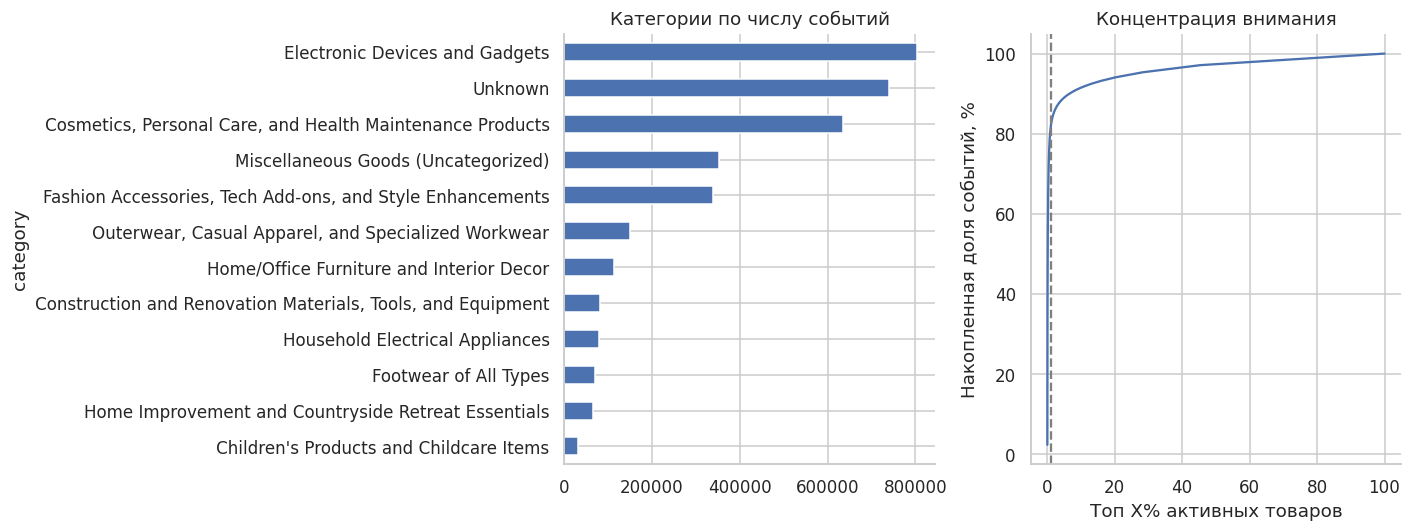

Неположительных price: 1,023,148 из 2,322,527
Пропуски price: 2882


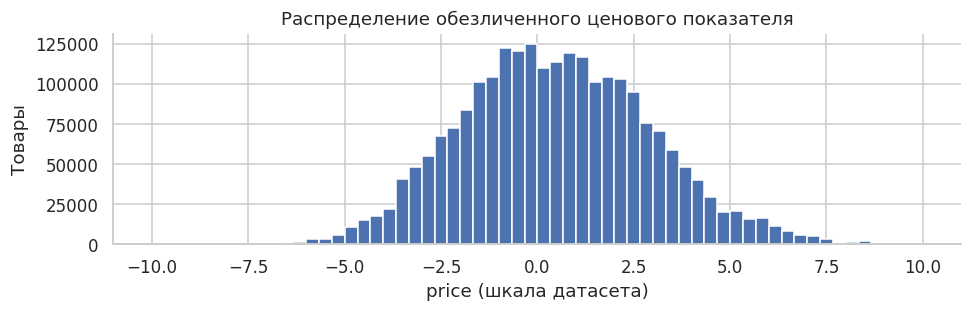

In [8]:
fig, ax = plt.subplots(1,2,figsize=(13,5))
category_summary.sort_values('events').tail(12)['events'].plot.barh(ax=ax[0],title='Категории по числу событий')
ax[1].plot(np.arange(1,len(ranked)+1)/len(ranked)*100,np.cumsum(ranked)/ranked.sum()*100)
ax[1].set(title='Концентрация внимания',xlabel='Топ X% активных товаров',ylabel='Накопленная доля событий, %')
ax[1].axvline(1,color='grey',linestyle='--'); plt.tight_layout(); plt.show()
price = items['price'].dropna()
print(f'Неположительных price: {price.le(0).sum():,} из {len(price):,}')
print('Пропуски price:', items['price'].isna().sum())
plt.figure(figsize=(9,3)); plt.hist(price,bins=60); plt.xlabel('price (шкала датасета)'); plt.ylabel('Товары'); plt.title('Распределение обезличенного ценового показателя'); plt.tight_layout(); plt.show()

## 5. Воронка взаимодействий

Единица анализа — пара **пользователь–товар в пределах одного дня**. Шаги: просмотр → клик строго после просмотра → внешний переход строго после клика. Для каждой пары берём первое подходящее событие на каждом шаге. Переходы между днями и события с одинаковыми временными метками не засчитываем. Это конверсия между наблюдаемыми действиями, не конверсия в покупку. Отношение общего числа кликов к просмотрам в предыдущем разделе — другой показатель.

,pairs,from_start_pct,from_previous_pct
View,2711336,100.00,NaN
Click after view,20786,0.77,0.77
Clickout after click,795,0.03,3.82


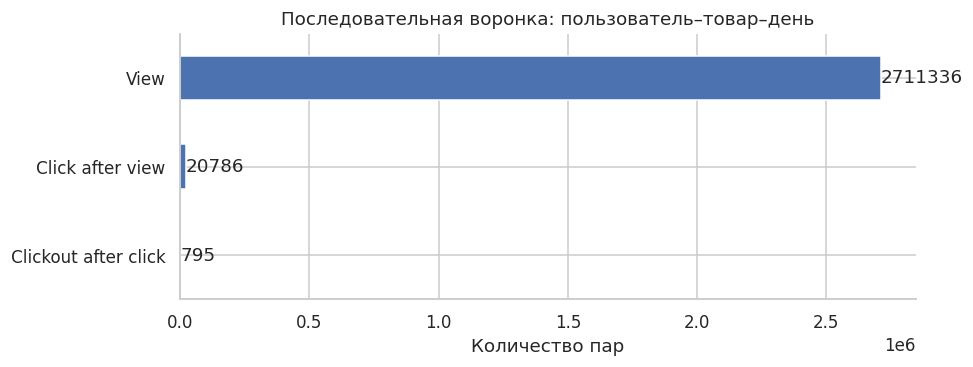

In [9]:
KEYS = ['user_id','item_id','day']
def ordered_funnel(frame):
    view = frame.loc[frame['action_type'].eq('view')].groupby(KEYS,sort=False)['timestamp'].min().rename('view_time').reset_index()
    click = frame.loc[frame['action_type'].eq('click'), KEYS+['timestamp']].merge(view,on=KEYS,how='inner',validate='many_to_one')
    click = click.loc[click['timestamp']>click['view_time']].groupby(KEYS,sort=False)['timestamp'].min().rename('click_time').reset_index()
    out = frame.loc[frame['action_type'].eq('clickout'), KEYS+['timestamp']].merge(click,on=KEYS,how='inner',validate='many_to_one')
    out = out.loc[out['timestamp']>out['click_time']].groupby(KEYS,sort=False)['timestamp'].min().reset_index()
    return pd.Series([len(view),len(click),len(out)],index=['View','Click after view','Clickout after click'],name='pairs')
funnel = ordered_funnel(events).to_frame()
assert funnel['pairs'].is_monotonic_decreasing
funnel['from_start_pct'] = funnel['pairs']/max(1,funnel['pairs'].iloc[0])*100
funnel['from_previous_pct'] = funnel['pairs']/funnel['pairs'].shift().replace(0,np.nan)*100
display(funnel.round(2))
ax = funnel['pairs'].plot.barh(figsize=(9,3.5),title='Последовательная воронка: пользователь–товар–день')
ax.invert_yaxis(); ax.bar_label(ax.containers[0],fmt='%d'); ax.set_xlabel('Количество пар'); plt.tight_layout(); plt.show()

## 6. Сегментация активных товаров

Товары без событий не включаем в KMeans: их нельзя разделить по наблюдаемому поведению. Используем логарифмы числа событий и пользователей, активные дни и относительные доли действий. Сегменты описываем по медианам, не присваивая им названия вроде «бестселлеры» без данных о продажах. Выбираем k на одной фиксированной подвыборке по silhouette среди решений, где каждый кластер содержит не менее 2% подвыборки; если таких нет, показываем наиболее сбалансированный вариант и предупреждение.

In [10]:
cluster_X = pd.DataFrame({'log_events':np.log1p(products['total']), 'log_users':np.log1p(products['unique_users']),
    'active_days':products['active_days'], 'click_share':products['click_share'],
    'clickout_share':products['clickout_share'], 'like_share':products['like_share']})
# StandardScaler сохраняет различия даже в редких долях; влияние таких признаков проверяем по профилям.
cluster_scaler = StandardScaler()
Z = cluster_scaler.fit_transform(cluster_X)
rng = np.random.default_rng(SEED)
idx = rng.choice(len(Z),size=min(12000,len(Z)),replace=False)
Z_fit = Z[idx]
score_idx = rng.choice(len(Z_fit),size=min(3000,len(Z_fit)),replace=False)
search = []; candidates = {}
with threadpool_limits(limits=4):
    for k in range(2, min(8,len(Z_fit)-1)+1):
        model = KMeans(n_clusters=k,n_init=5,random_state=SEED).fit(Z_fit)
        labels = model.labels_
        if np.unique(labels).size != k or not 1 < np.unique(labels[score_idx]).size < len(score_idx):
            continue
        sil = silhouette_score(Z_fit[score_idx],labels[score_idx])
        min_share = np.bincount(labels,minlength=k).min()/len(labels)
        search.append({'k':k,'silhouette':sil,'min_share':min_share})
        candidates[k] = model
assert search, 'Недостаточно разнообразия для кластеризации'
cluster_search = pd.DataFrame(search)
valid = cluster_search[cluster_search['min_share']>=.02]
if valid.empty:
    print('Предупреждение: нет решения с минимальной долей 2%.')
    best_k = int(cluster_search.sort_values(['min_share','silhouette'],ascending=False).iloc[0]['k'])
else:
    best_k = int(valid.loc[valid['silhouette'].idxmax(),'k'])
with threadpool_limits(limits=4):
    products['cluster'] = candidates[best_k].predict(Z)
display(cluster_search.round(3)); print('Выбранное k:',best_k)

,k,silhouette,min_share
0,2,0.668,0.123
1,3,0.716,0.065
2,4,0.726,0.010
3,5,0.686,0.013
4,6,0.690,0.001
5,7,0.663,0.001
6,8,0.669,0.001


Выбранное k: 3


,items,median_events,median_users,median_active_days,click_share,clickout_share,like_share,item_share_pct
cluster,,,,,,,,
0,153550,1.0,1.0,1.0,0.008,0.000,0.001,82.629
1,11457,2.0,1.0,1.0,0.679,0.101,0.004,6.165
2,20824,12.0,10.0,5.0,0.044,0.008,0.001,11.206


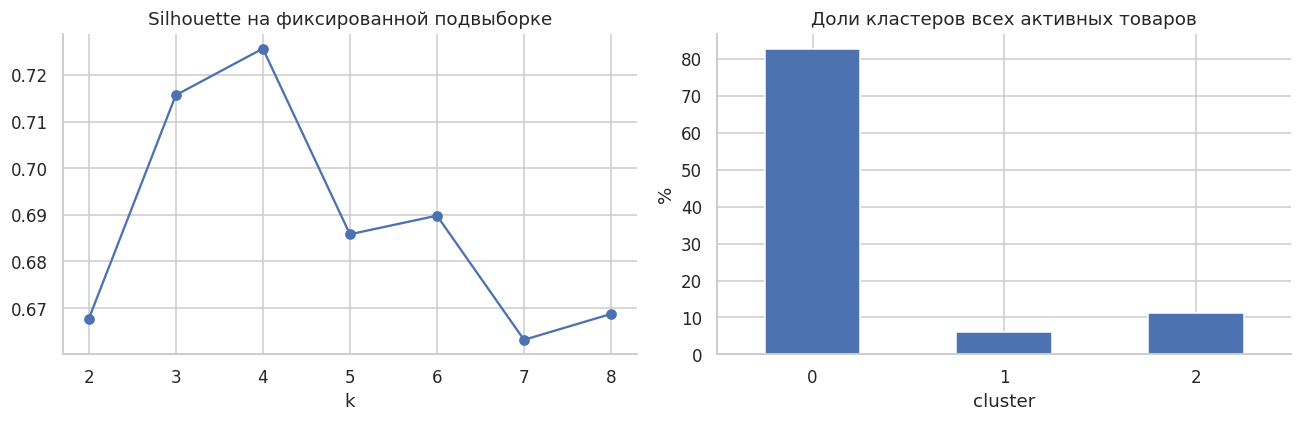

In [11]:
cluster_profile = products.groupby('cluster').agg(items=('item_id','size'),median_events=('total','median'),median_users=('unique_users','median'),median_active_days=('active_days','median'),click_share=('click_share','mean'),clickout_share=('clickout_share','mean'),like_share=('like_share','mean'))
cluster_profile['item_share_pct'] = 100*cluster_profile['items']/len(products)
display(cluster_profile.round(3))
fig, ax = plt.subplots(1,2,figsize=(12,4))
cluster_search.plot(x='k',y='silhouette',marker='o',legend=False,ax=ax[0],title='Silhouette на фиксированной подвыборке')
cluster_profile['item_share_pct'].plot.bar(ax=ax[1],rot=0,title='Доли кластеров всех активных товаров',ylabel='%')
plt.tight_layout(); plt.show()
if cluster_profile['item_share_pct'].min()<2: print('На полном наборе есть малые кластеры: интерпретировать осторожно.')

## 7. Прогноз активности на следующий день

**Бизнес-вопрос:** какие уже наблюдавшиеся товары получат повышенное число взаимодействий завтра? Это может помочь в планировании аналитического мониторинга и приоритизации ассортимента, но не доказывает эффективность продвижения.

Для целевого дня D признаки вычисляем только по дням D−2 и D−1. Кандидаты — товары, активные хотя бы один раз в эти два дня; если завтра событий нет, целевое число равно нулю. Новые и давно неактивные товары вне этой постановки. Не используем цену, идентификаторы, будущие события или кластеры, рассчитанные по всей неделе, как признаки. Товары могут повторяться в разных временных окнах, поскольку прогноз делается для уже наблюдавшихся товаров.

При семи днях доступны пять целевых дней: первые три — train, четвёртый — validation, пятый — test. Порог высокой активности определяем только на train (80-й перцентиль, округление вверх, минимум 2 события). Из-за дискретности доля положительных примеров может отличаться от 20%.

In [12]:
def make_forecast_frame(frame, target_day):
    history = frame.loc[frame['day'].between(target_day-2,target_day-1)]
    f = product_features(history)
    recent = history.loc[history['day'].eq(target_day-1)].groupby('item_id',sort=False).size()
    f['last_day'] = f['item_id'].map(recent).fillna(0).astype('int32')
    f['previous_day'] = f['total']-f['last_day']
    f['trend'] = np.log1p(f['last_day'])-np.log1p(f['previous_day'])
    target = frame.loc[frame['day'].eq(target_day)].groupby('item_id',sort=False).size()
    f['target_events'] = f['item_id'].map(target).fillna(0).astype('int32')
    f['target_day'] = target_day
    return f

forecast = pd.concat([make_forecast_frame(events,d) for d in days[2:]],ignore_index=True)
train = forecast.loc[forecast['target_day']<days[-2]].copy()
val = forecast.loc[forecast['target_day'].eq(days[-2])].copy()
test = forecast.loc[forecast['target_day'].eq(days[-1])].copy()
assert train['target_day'].max()<val['target_day'].min()<test['target_day'].min()
threshold = max(2,int(np.ceil(train['target_events'].quantile(.8))))
for df in [train,val,test]:
    df['high_activity'] = df['target_events'].ge(threshold).astype('int8')
FEATURES = ['n_view','n_click','n_clickout','n_like','total','unique_users','active_days','click_share','clickout_share','like_share','last_day','previous_day','trend']
assert not set(FEATURES)&{'target_events','high_activity','target_day','item_id','cluster','price'}
# log1p только для неотрицательных счётчиков, доли и trend оставляем без преобразования.
COUNT_COLS = ['n_view','n_click','n_clickout','n_like','total','unique_users','last_day','previous_day']
def matrix(df):
    X = df[FEATURES].astype('float32').copy()
    X[COUNT_COLS] = np.log1p(X[COUNT_COLS])
    return X
X_train,X_val,X_test = map(matrix,[train,val,test])
y_train,y_val,y_test = [df['high_activity'].to_numpy() for df in [train,val,test]]
print('Порог высокой активности:',threshold)
display(pd.DataFrame([{'split':name,'days':str(sorted(df['target_day'].unique().tolist())), 'rows':len(df),'positive_pct':100*df['high_activity'].mean()} for name,df in [('train',train),('val',val),('test',test)]]).round(2))
assert all(np.unique(y).size==2 for y in [y_train,y_val,y_test]), 'Порог дал один класс: пересмотрите постановку на train'

Порог высокой активности: 2


,split,days,rows,positive_pct
0,train,"[1084, 1085, 1086]",227413,15.42
1,val,[1087],80000,14.99
2,test,[1088],81113,14.01


### 7.1. Классификация

Сравниваем модель с простым ранжированием по активности предыдущего дня и константной вероятностью класса из train. Logistic Regression — линейная модель, HistGradientBoosting — нелинейная модель для табличных данных. Основная метрика — Average Precision (AP), учитывающая качество ранжирования положительных примеров при дисбалансе. ROC-AUC — дополнительная метрика. Модель выбираем по AP на validation; порог решения по F1 также выбираем на validation. Test не используется для выбора модели или порога.

In [13]:
models_cls = {'Logistic regression':make_pipeline(StandardScaler(),LogisticRegression(max_iter=300,random_state=SEED)),
              'HistGradientBoosting':HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=15,learning_rate=.1,random_state=SEED,early_stopping=False)}
val_scores = {}; cls_rows=[]
with threadpool_limits(limits=4):
    for name,model in models_cls.items():
        model.fit(X_train,y_train)
        scores=model.predict_proba(X_val)[:,1]
        val_scores[name]=scores
        cls_rows.append({'model':name,'AP':average_precision_score(y_val,scores),'ROC_AUC':roc_auc_score(y_val,scores)})
cls_val = pd.DataFrame(cls_rows).sort_values('AP',ascending=False)
best_cls = cls_val.iloc[0]['model']
# Фиксированная сетка порогов; в случае равенства берём первый.
proba_val = val_scores[best_cls]
cutoffs = np.linspace(.05,.95,37)
cutoff = float(cutoffs[np.argmax([f1_score(y_val,proba_val>=c,zero_division=0) for c in cutoffs])])
print('Выбор по validation:',best_cls,'порог:',round(cutoff,3))
display(cls_val.round(4))
print('Validation AP, активность предыдущего дня:',round(average_precision_score(y_val,val['last_day']),4))

Выбор по validation: HistGradientBoosting порог: 0.325


,model,AP,ROC_AUC
1,HistGradientBoosting,0.6526,0.8405
0,Logistic regression,0.6444,0.8376


Validation AP, активность предыдущего дня: 0.566


Test: precision 0.6251 recall 0.5651 F1 0.5936


,model,AP,ROC_AUC
0,Constant baseline,0.1401,0.5000
1,Previous-day ranking,0.5400,0.7888
2,HistGradientBoosting,0.6266,0.8364


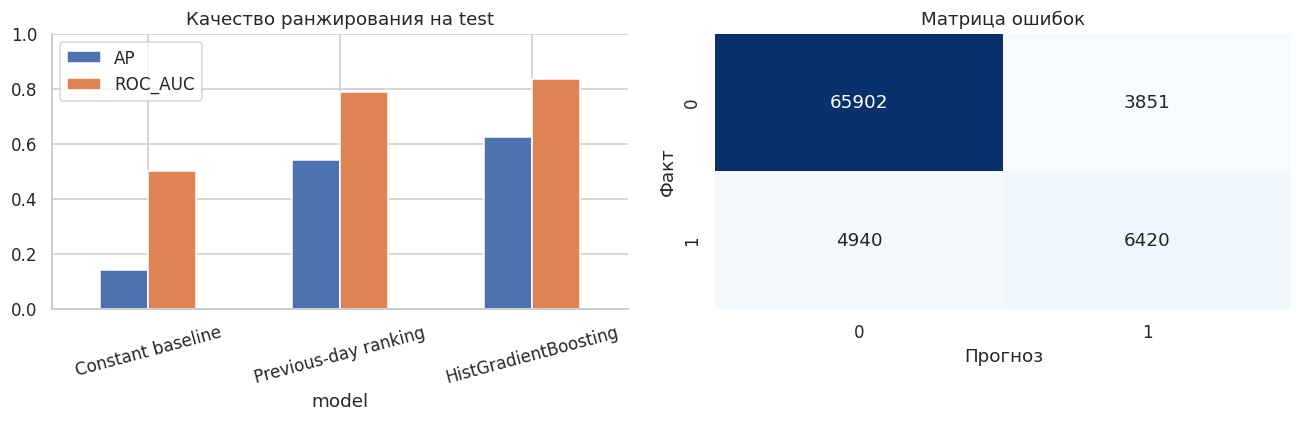

In [14]:
with threadpool_limits(limits=4):
    proba_test = models_cls[best_cls].predict_proba(X_test)[:,1]
cls_test = pd.DataFrame([
    {'model':'Constant baseline','AP':average_precision_score(y_test,np.full(len(test),y_train.mean())),'ROC_AUC':.5},
    {'model':'Previous-day ranking','AP':average_precision_score(y_test,test['last_day']),'ROC_AUC':roc_auc_score(y_test,test['last_day'])},
    {'model':best_cls,'AP':average_precision_score(y_test,proba_test),'ROC_AUC':roc_auc_score(y_test,proba_test)}])
pred_cls = (proba_test>=cutoff).astype(int)
print('Test: precision',round(precision_score(y_test,pred_cls,zero_division=0),4),'recall',round(recall_score(y_test,pred_cls,zero_division=0),4),'F1',round(f1_score(y_test,pred_cls,zero_division=0),4))
display(cls_test.round(4))
fig, ax=plt.subplots(1,2,figsize=(12,4))
cls_test.set_index('model')[['AP','ROC_AUC']].plot.bar(ax=ax[0],rot=15,ylim=(0,1),title='Качество ранжирования на test')
sns.heatmap(confusion_matrix(y_test,pred_cls,labels=[0,1]),annot=True,fmt='d',cmap='Blues',ax=ax[1],cbar=False); ax[1].set(title='Матрица ошибок',xlabel='Прогноз',ylabel='Факт')
plt.tight_layout(); plt.show()

### 7.2. Регрессия: повторный эксперимент

Прогнозируем число событий завтра. В первом полном запуске Poisson-бустинг дал MAE порядка 5,22×10²⁸ на validation, поэтому был исключён; причина численной нестабильности требует отдельной диагностики. Проверяем альтернативу: бустинг с абсолютной ошибкой на логарифмической шкале целевой переменной, обратное преобразование через `expm1`, а также простые прогнозы на основе истории.

Наивный прогноз равен числу событий предыдущего дня. Скорректированный наивный прогноз умножает это число на коэффициент. Выбор по MAE на validation. Корректирующий коэффициент наивного прогноза выбирается только на validation. Этот повторный эксперимент использует уже изученный тестовый день, поэтому его результат следует считать исследовательским; для независимой проверки нужен новый временной период.


In [15]:
r_train, r_val, r_test = [df['target_events'].to_numpy() for df in [train, val, test]]

# Baseline: константа, последний день, среднее за два дня.
def baseline_preds(df):
    return {
        'Train mean': np.full(len(df), r_train.mean()),
        'Train median': np.full(len(df), np.median(r_train)),
        'Naive forecast': df['last_day'].to_numpy(dtype=float),
        'Two-day mean': df['total'].to_numpy(dtype=float) / 2
    }

# Подбор масштаба активности предыдущего дня на validation.
factors = np.linspace(0.0, 1.5, 31)
val_yesterday = val['last_day'].to_numpy(dtype=float)
scale = float(min(factors, key=lambda a: mean_absolute_error(r_val, a * val_yesterday)))

reg = HistGradientBoostingRegressor(
    loss='absolute_error', max_iter=100, max_leaf_nodes=15,
    learning_rate=.05, min_samples_leaf=50, l2_regularization=1.0,
    random_state=SEED, early_stopping=False
)
with threadpool_limits(limits=4):
    reg.fit(X_train, np.log1p(r_train))
    reg_val = np.maximum(0.0, np.expm1(reg.predict(X_val)))

reg_val_preds = baseline_preds(val)
reg_val_preds['Adjusted naive forecast'] = scale * val_yesterday
if np.isfinite(reg_val).all():
    reg_val_preds['Log-target boosting'] = reg_val
else:
    print('Log-target boosting: нечисловые прогнозы, модель исключена.')

reg_val_metrics = pd.DataFrame([
    {'model': name, 'MAE': mean_absolute_error(r_val, pred)}
    for name, pred in reg_val_preds.items()
]).sort_values('MAE')
best_reg = reg_val_metrics.iloc[0]['model']
display(reg_val_metrics.round(4))
print('Корректирующий коэффициент:', scale)
print('Выбор по validation:', best_reg)


,model,MAE
4,Adjusted naive forecast,2.9586
2,Naive forecast,3.1677
3,Two-day mean,3.3518
5,Log-target boosting,5.1873
1,Train median,5.7347
0,Train mean,10.5888


Корректирующий коэффициент: 0.8500000000000001
Выбор по validation: Adjusted naive forecast


,model,MAE,RMSE,R2
0,Train mean,10.196,89.242,-0.000
1,Train median,5.245,89.390,-0.003
2,Naive forecast,2.606,33.840,0.856
3,Two-day mean,2.972,40.238,0.797
4,Adjusted naive forecast,2.375,31.357,0.877


,actual,predicted,items
predicted_group,,,
"(-0.001, 0.85]",0.32,0.41,63972
"(0.85, 1.7]",1.02,1.70,7474
"(1.7, 2.55]",1.65,2.55,2943
"(2.55, 8803.45]",58.40,55.53,6724


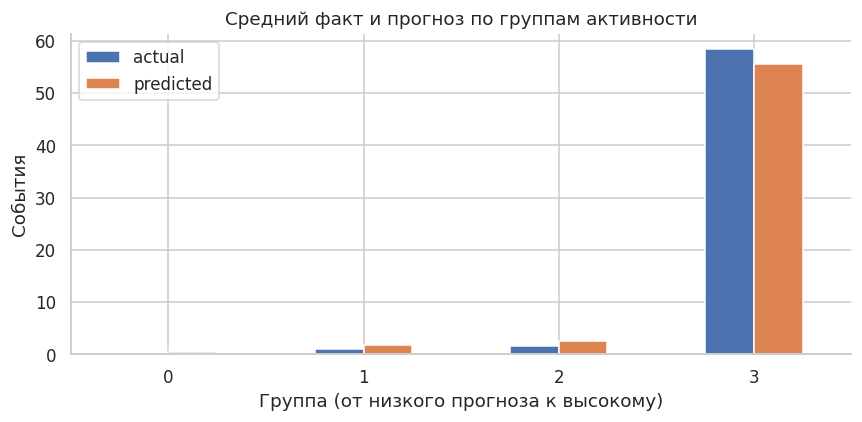

In [16]:
reg_test_preds = baseline_preds(test)
if best_reg == 'Adjusted naive forecast':
    reg_test_preds[best_reg] = scale * test['last_day'].to_numpy(dtype=float)
elif best_reg == 'Log-target boosting':
    with threadpool_limits(limits=4):
        reg_test_preds[best_reg] = np.maximum(0.0, np.expm1(reg.predict(X_test)))

assert all(np.isfinite(p).all() for p in reg_test_preds.values()), 'Неконечный прогноз'
reg_test = pd.DataFrame([
    {'model': n, 'MAE': mean_absolute_error(r_test, p),
     'RMSE': np.sqrt(mean_squared_error(r_test, p)), 'R2': r2_score(r_test, p)}
    for n, p in reg_test_preds.items()
])
display(reg_test.round(3))
r_pred = reg_test_preds[best_reg]
calibration = pd.DataFrame({'actual': r_test, 'predicted': r_pred})
calibration['predicted_group'] = (
    pd.qcut(calibration['predicted'], q=10, duplicates='drop')
    if calibration['predicted'].nunique() > 1 else 'All'
)
calibration_summary = calibration.groupby('predicted_group', observed=True).agg(
    actual=('actual','mean'), predicted=('predicted','mean'), items=('actual','size')
)
display(calibration_summary.round(2))
fig, ax = plt.subplots(figsize=(8,4))
calibration_summary[['actual','predicted']].reset_index(drop=True).plot.bar(
    ax=ax, rot=0, title='Средний факт и прогноз по группам активности'
)
ax.set(xlabel='Группа (от низкого прогноза к высокому)', ylabel='События')
plt.tight_layout()
plt.show()


## 8. Производительность обработки данных

Сравниваем один и тот же результат: число просмотров по товарам. Три метода — цикл Python с Counter, Pandas groupby и value_counts. На каждом размере выполняем прогрев и пять замеров, чередуя порядок методов; используем медиану. Время зависит от среды и данных. Не предполагаем заранее, что Pandas быстрее.

,rows,method,median_ms,min_ms,max_ms
0,10000,Python Counter,2.56,2.53,2.62
1,10000,Pandas groupby,3.34,3.27,3.38
2,10000,Pandas value_counts,3.04,2.99,3.18
3,100000,Python Counter,29.48,29.30,31.36
4,100000,Pandas groupby,24.31,23.09,25.19
5,100000,Pandas value_counts,21.91,21.79,22.23
6,500000,Python Counter,278.40,271.15,300.09
7,500000,Pandas groupby,167.08,116.08,180.77
8,500000,Pandas value_counts,168.32,113.02,184.05


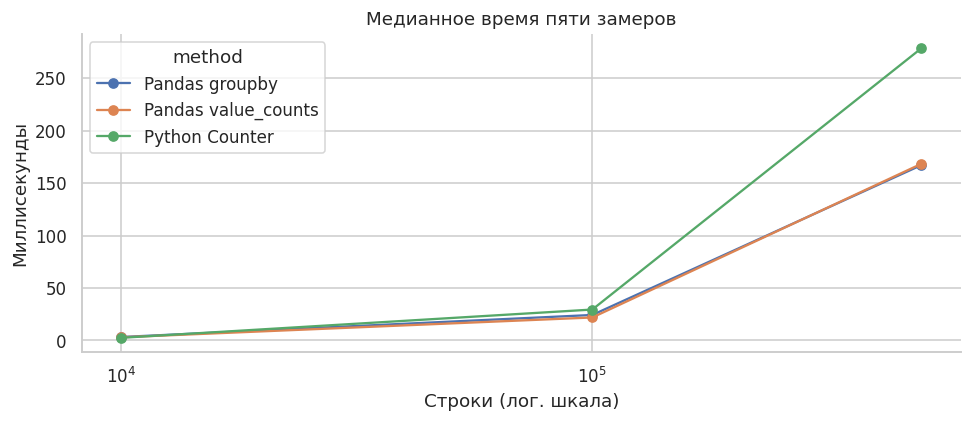

In [17]:
def count_python(df):
    return dict(Counter(i for i,a in zip(df['item_id'],df['action_type']) if a=='view'))
def count_groupby(df):
    return df.loc[df['action_type'].eq('view')].groupby('item_id',sort=False).size().to_dict()
def count_value_counts(df):
    return df.loc[df['action_type'].eq('view'),'item_id'].value_counts(sort=False).to_dict()
methods={'Python Counter':count_python,'Pandas groupby':count_groupby,'Pandas value_counts':count_value_counts}
bench_rows=[]
for size in sorted(set(min(n,len(events)) for n in [10000,100000,500000])):
    sample=events[['item_id','action_type']].sample(n=size,random_state=SEED)
    reference=count_python(sample)
    for fun in methods.values(): assert fun(sample)==reference
    timings={name:[] for name in methods}
    for repeat in range(5):
        for name in np.random.default_rng(SEED+repeat).permutation(list(methods)):
            t=perf_counter(); result=methods[name](sample); timings[name].append(perf_counter()-t)
    for name,values in timings.items(): bench_rows.append({'rows':size,'method':name,'median_ms':1000*np.median(values),'min_ms':1000*np.min(values),'max_ms':1000*np.max(values)})
benchmark=pd.DataFrame(bench_rows)
display(benchmark.round(2))
ax=benchmark.pivot(index='rows',columns='method',values='median_ms').plot(marker='o',figsize=(9,4),logx=True,title='Медианное время пяти замеров'); ax.set(xlabel='Строки (лог. шкала)',ylabel='Миллисекунды'); plt.tight_layout(); plt.show()

## 9. Итоговые результаты и ограничения

Следующая ячейка формирует выводы из текущих вычислений, а не из заранее записанных метрик. Это позволяет избежать устаревших результатов после повторного запуска.

In [18]:
ap_model=cls_test.loc[cls_test['model'].eq(best_cls),'AP'].iloc[0]
ap_base=cls_test.loc[cls_test['model'].eq('Previous-day ranking'),'AP'].iloc[0]
mae_model=reg_test.loc[reg_test['model'].eq(best_reg),'MAE'].iloc[0]
mae_base=reg_test.loc[reg_test['model'].eq('Naive forecast'),'MAE'].iloc[0]
print(f'1. {n_events:,} событий, {n_users:,} пользователей, {n_active_items:,} активных товаров.')
print(f'2. Повторная активность: {repeat_share:.1%}; охват каталога: {coverage:.2%}.')
print(f'3. Топ-1% активных товаров получает {top_share:.1%} событий.')
print(f'4. Воронка: {funnel.iloc[-1]["from_start_pct"]:.2f}% пар дошли до внешнего перехода.')
print(f'5. Кластеров: {best_k}; крупнейший содержит {cluster_profile["item_share_pct"].max():.1f}% активных товаров.')
print(f'6. Классификация: {best_cls}; AP={ap_model:.4f}, ранжирование по активности предыдущего дня={ap_base:.4f}.')
print('   Модель улучшает baseline по AP.' if ap_model>ap_base else '   Преимущество над простым ранжированием не подтверждено.')
print('7. Регрессия: повторный эксперимент на ранее изученном test-дне.')
print(f'   Регрессия: {best_reg}; MAE={mae_model:.3f}, наивный прогноз по предыдущему дню={mae_base:.3f}.')
print('   Выбранный метод улучшает baseline по MAE.' if mae_model<mae_base else '   Улучшение над наивным прогнозом по предыдущему дню не подтверждено.')
for size,g in benchmark.groupby('rows'):
    fastest=g.loc[g['median_ms'].idxmin()]; print(f'8. {size:,} строк: {fastest["method"]}, {fastest["median_ms"]:.2f} мс.')

1. 3,515,262 событий, 223,443 пользователей, 185,831 активных товаров.
2. Повторная активность: 45.6%; охват каталога: 7.99%.
3. Топ-1% активных товаров получает 81.7% событий.
4. Воронка: 0.03% пар дошли до внешнего перехода.
5. Кластеров: 3; крупнейший содержит 82.6% активных товаров.
6. Классификация: HistGradientBoosting; AP=0.6266, ранжирование по активности предыдущего дня=0.5400.
   Модель улучшает baseline по AP.
7. Регрессия: повторный эксперимент на ранее изученном test-дне.
   Регрессия: Adjusted naive forecast; MAE=2.375, наивный прогноз по предыдущему дню=2.606.
   Выбранный метод улучшает baseline по MAE.
8. 10,000 строк: Python Counter, 2.56 мс.
8. 100,000 строк: Pandas value_counts, 21.91 мс.
8. 500,000 строк: Pandas groupby, 167.08 мс.


### Как использовать результаты

- Если внимание концентрируется в малой части ассортимента, стоит исследовать экспозицию товаров и доступность категорий; сами по себе просмотры не измеряют спрос независимо от выдачи.
- Воронка позволяет найти шаг с наибольшей потерей наблюдаемых пар. Причины требуют дополнительных данных или эксперимента.
- Профили кластеров помогают сформулировать гипотезы о поведении, но сегменты нужно проверить на другом периоде.
- Прогноз имеет практический смысл только при устойчивом выигрыше у простых baseline на новых периодах. До этого не следует использовать его для решений автоматически.

**Ограничения:** семь дней наблюдения; только один validation-день и один test-день; возможная зависимость наблюдений по одним и тем же товарам; обезличивание атрибутов; отсутствие заказов, выручки, показов выдачи и информации о регистрации; воронка ограничена одним днём; прогноз не охватывает новые товары. Для дальнейшей работы нужны более длинная история и backtesting на нескольких периодах.

**Ключевые результаты полного запуска.** Концентрация взаимодействий у верхнего 1% активных товаров (81,71%) и охват каталога (7,99%) дают основание проверить видимость ассортимента. Воронка фиксирует 0,77% переходов от просмотра к клику в рамках выбранной единицы анализа; для объяснения причин нужны данные о показах и пользовательском интерфейсе. В классификации HistGradientBoosting улучшил AP относительно ранжирования по активности предыдущего дня (0,6266 против 0,5400). В регрессии наивный прогноз с корректирующим коэффициентом (коэффициент 0,85) оказался лучшим по MAE на validation; сложная модель преимущества не дала. Результат регрессии требует независимой проверки на новом периоде. Для агрегации на 500 тыс. строк в данном запуске быстрее groupby, на 100 тыс. — value_counts; абсолютные времена зависят от среды.
